In [1]:
import xarray as xr
# import matplotlib as plt
from matplotlib import pyplot as plt
import pandas as pd
import geopandas as gpd
from math import sqrt
import seaborn as sns
import numpy as np
import cartopy
from scipy.stats import kurtosis, norm

from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import BayesianRidge
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import mean_squared_error, r2_score 
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings('ignore')

#Choose whether to save plots
save_plots = False

# Change the matplotlib dpi to increase or decrease output size in vscode
plt.rcParams['figure.dpi'] = 150 

# Change some of the default xarray settings
xr.set_options(keep_attrs=True, display_expand_data=False)

def rmse(x,y):
    out = sqrt(mean_squared_error(x,y))
    return out


In [2]:
datapath = "/home/nlring/Documents/01_Research/larc-chicago-haq/datasets/"
dat = pd.read_csv(datapath+"seasonal-dayofweek-no2-estimates.csv")



def F_pixel_stats(dat):
   y_true = dat.sfc_no2_mean
   y_pred = dat.no2_estimate
   bias = (y_pred-y_true).mean()
   rmse = sqrt(mean_squared_error(y_true, y_pred))
   r2 = r2_score(y_true, y_pred)
   # covar = np.cov(y_true, y_pred, ddof=0)
   corr_coef = np.corrcoef(y_true, y_pred, rowvar=False)[0,1]
   covar = np.nan
   out = pd.Series({'r2': r2, 'bias': bias, 'rmse':rmse,
                    'covar': covar, 'corr_coef': corr_coef})
   return out


pixel_stats_wide = (
    dat.groupby(['latitude','longitude','season','split'])
    .apply(F_pixel_stats)
    .reset_index())

pixel_stats_long = (
    dat.groupby(['latitude','longitude','season','split'])
    .apply(F_pixel_stats)
    .melt(ignore_index=False)
    .reset_index()
               )

print(dat)
print(pixel_stats_wide)
print(pixel_stats_long)

        Unnamed: 0             datetime  latitude  longitude  sfc_no2_mean  \
0            36003  2025-09-04 12:00:00     41.83     -87.65     14.566667   
1            30971  2025-09-04 12:00:00     41.69     -87.53     13.080000   
2            30901  2025-09-04 12:00:00     41.83     -87.67     13.356667   
3            34617  2025-09-04 12:00:00     41.67     -87.67     12.597500   
4            30820  2025-09-04 12:00:00     41.79     -87.77      9.325000   
...            ...                  ...       ...        ...           ...   
143034      115816  2026-05-31 23:00:00     41.97     -87.85     11.105909   
143035      118087  2026-05-31 23:00:00     41.95     -87.85     11.627000   
143036      116408  2026-05-31 23:00:00     41.97     -87.83     11.930909   
143037      116918  2026-05-31 23:00:00     42.01     -87.77     10.641000   
143038      115776  2026-05-31 23:00:00     41.97     -87.87     14.002581   

        col_no2_mean  no2_estimate  weekday  season  split  res

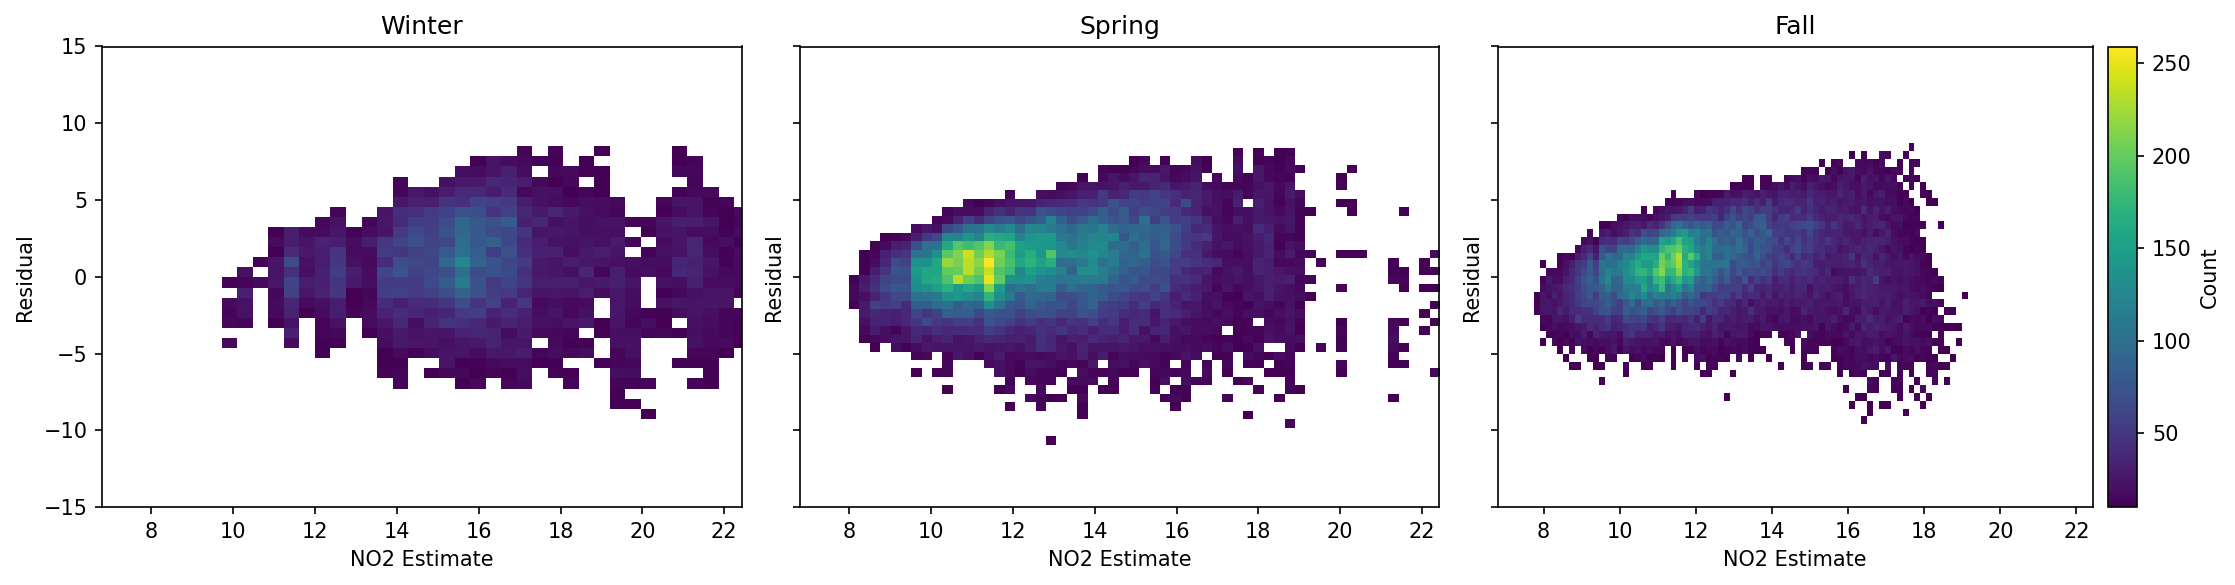

In [67]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.colors as mcolors

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

season_order = ['Winter', 'Spring', 'Fall']
threshold = 10 
bins = 100 

# Compute overall vmax for shared colorscale
vmax = 0
for season in season_order:
    season_data = dat[dat['season'] == season]
    counts, _, _ = np.histogram2d(season_data['no2_estimate'], season_data['residual'], bins=bins)
    vmax = max(vmax, counts.max())

# Create histograms with shared colorscale and threshold
for idx, season in enumerate(season_order):
    season_data = dat[dat['season'] == season]
    counts, xedges, yedges = np.histogram2d(season_data['no2_estimate'], season_data['residual'], bins=bins)
    
    # Create masked array where values < threshold are masked
    counts_masked = np.ma.masked_where(counts.T < threshold, counts.T)
    
    # Plot with imshow
    im = axes[idx].imshow(counts_masked, origin='lower', cmap='viridis', aspect='auto',
                         extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
                         vmin=threshold, vmax=vmax)
    
    axes[idx].set_xlabel('NO2 Estimate')
    axes[idx].set_ylabel('Residual')
    axes[idx].set_title(f'{season}')
    axes[idx].set_ylim(-15,15)

# Add a single colorbar for all subplots
divider = make_axes_locatable(axes[-1])
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = plt.colorbar(im, cax=cax, label='Count')

plt.tight_layout()
plt.savefig('heatmap-estimate-vs-residual.png')
plt.show()

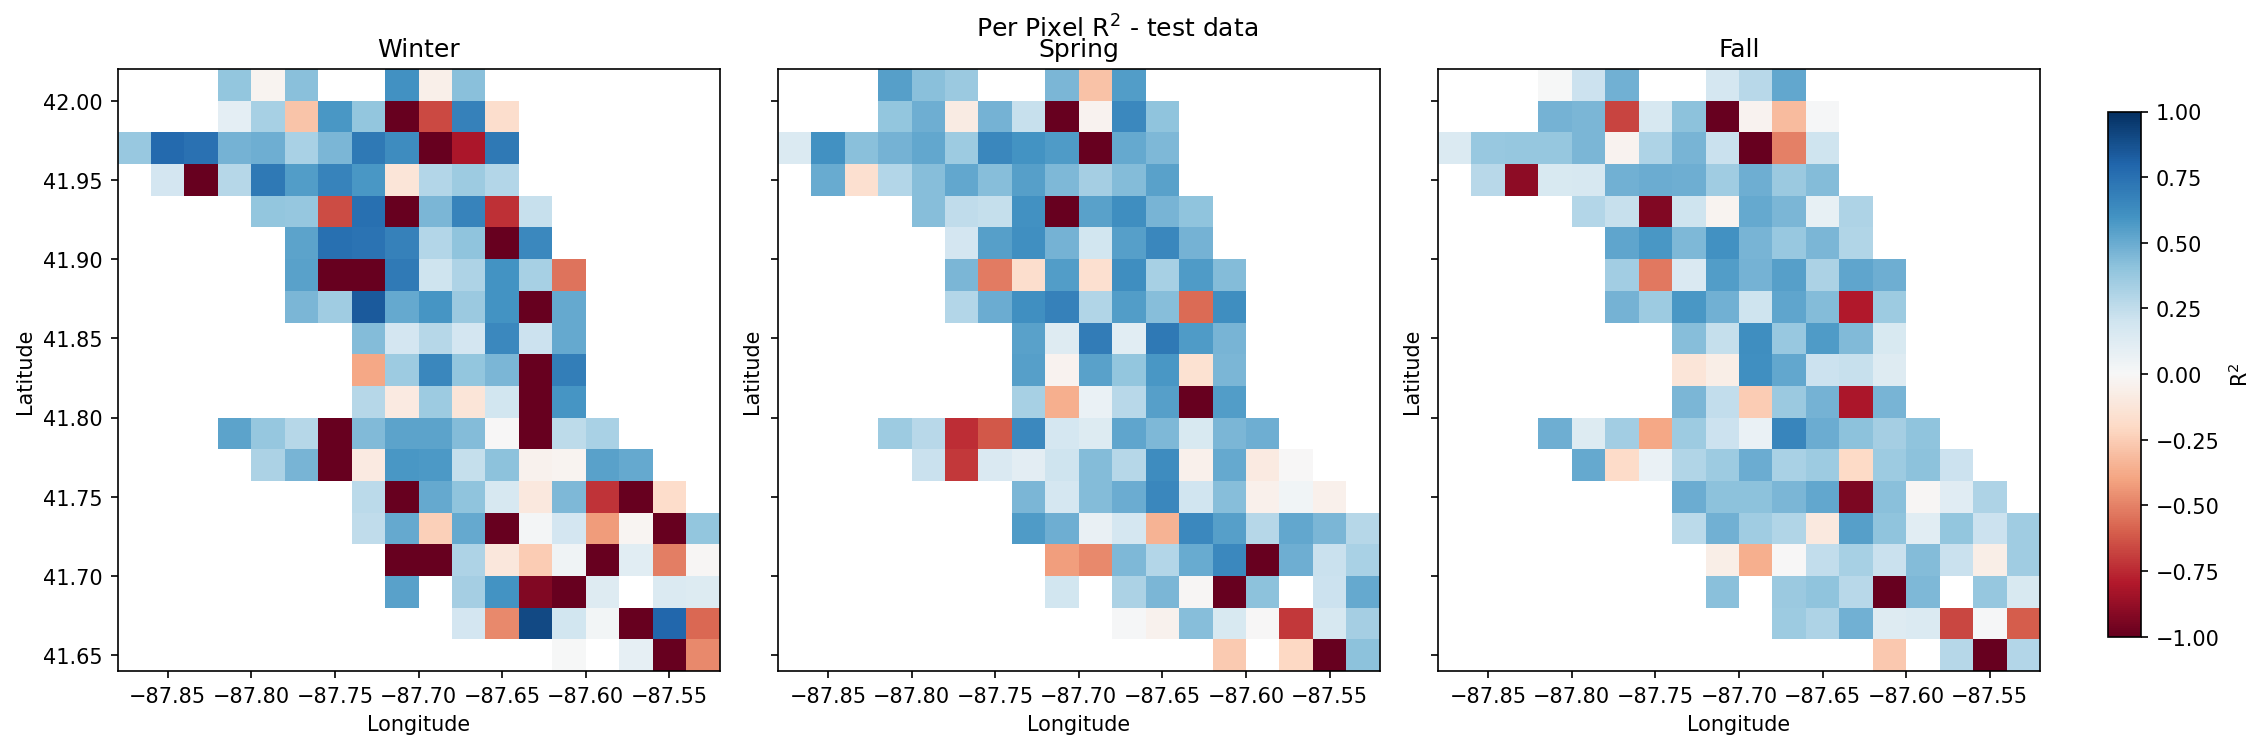

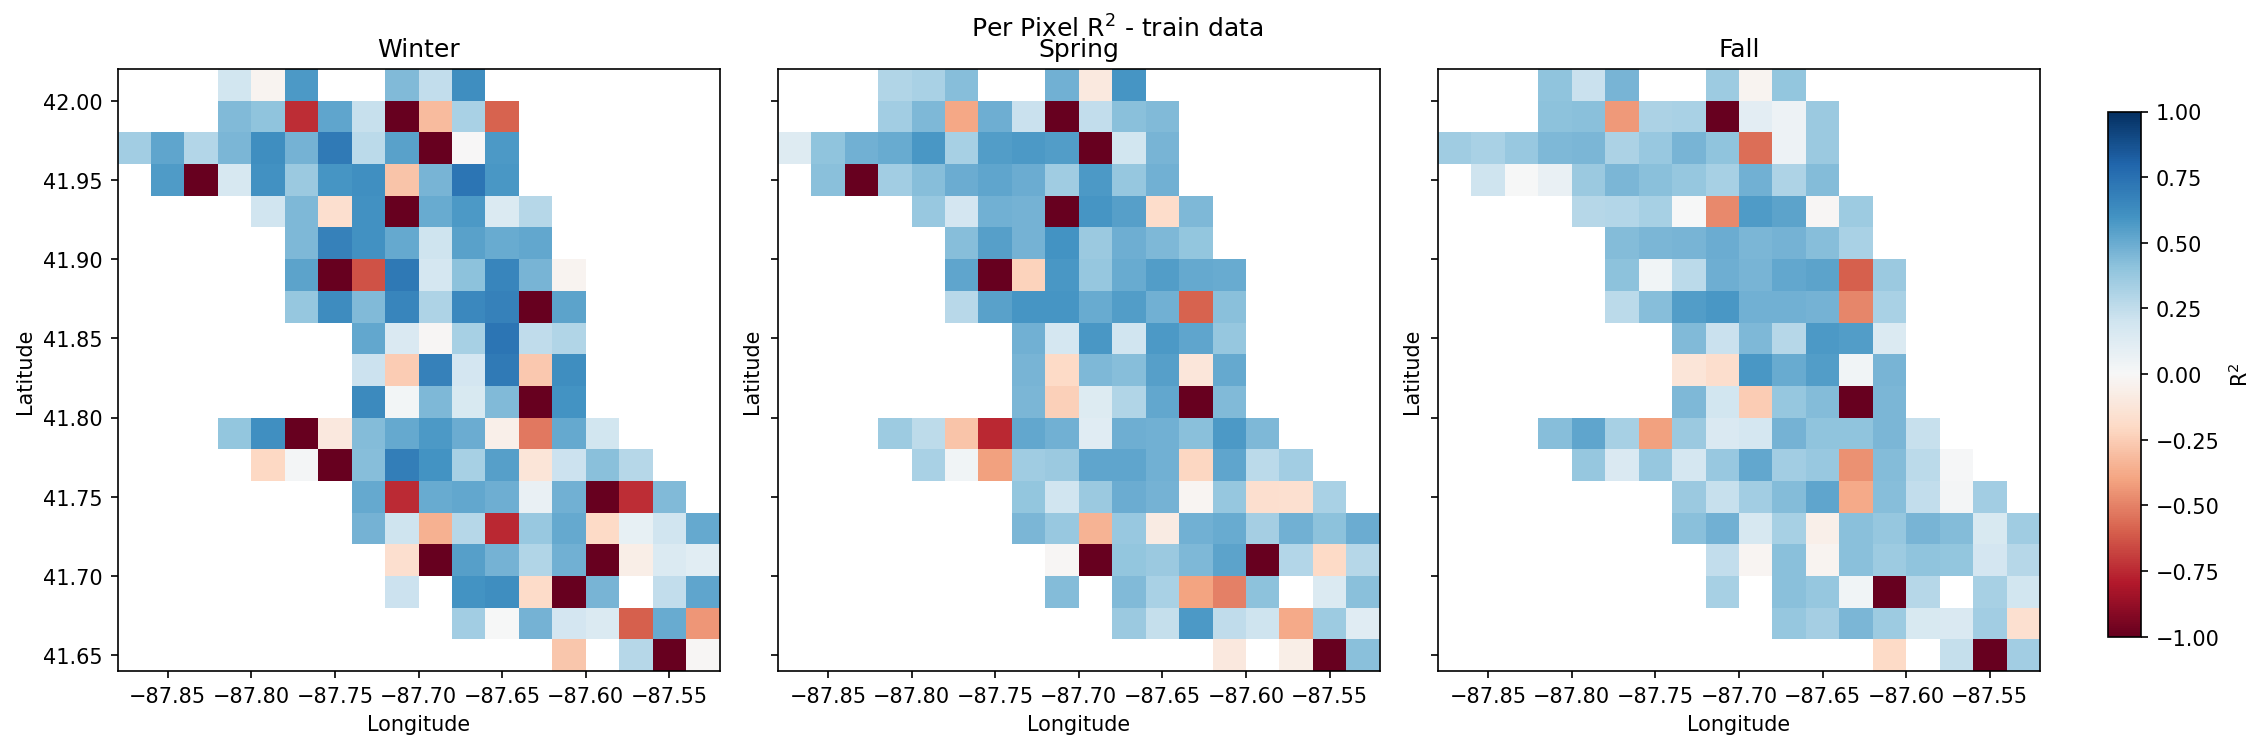

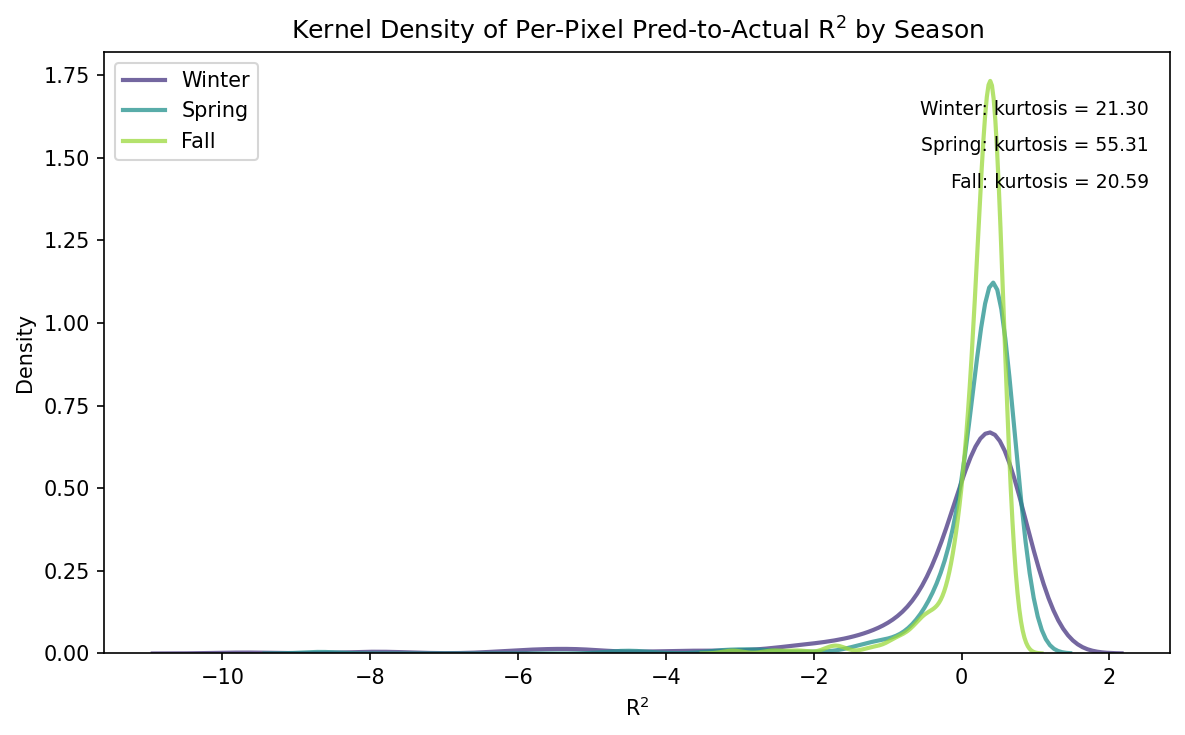

In [3]:
season_order = ['Winter', 'Spring', 'Summer', 'Fall']
seasonal_maps = []
splits = ['test','train']


for split in splits:
    seasonal_maps = []
    for season in season_order:
        season_subset = pixel_stats_long.loc[
            (pixel_stats_long['season'] == season) & (pixel_stats_long['variable'] == 'r2') & (pixel_stats_long['split']==split),
            ['latitude', 'longitude', 'value']
        ]
        if season_subset.empty:
            continue

        season_rast = season_subset.set_index(['latitude', 'longitude']).to_xarray()
        seasonal_maps.append((season, season_rast['value']))

    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5), sharex=True, sharey=True)
    axes = axes.flatten()
    mappable = None

    for ax, (season, mean_map) in zip(axes, seasonal_maps):
        mappable = mean_map.plot(
            x='longitude',
            y='latitude',
            cmap='RdBu',
            ax=ax,
            add_colorbar=False,
            vmin=-1,
            vmax=1
        )
        ax.set_box_aspect(1)
        ax.set_title(season)
        ax.set_xlabel('Longitude')
        ax.set_ylabel('Latitude')

    for ax in axes[len(seasonal_maps):]:
        ax.set_visible(False)

    # Reserve space at right for a single shared colorbar
    plt.tight_layout(rect=[0, 0, 0.92, 0.97])

    if mappable is not None:
        cax = fig.add_axes([0.94, 0.15, 0.015, 0.7])
        fig.colorbar(mappable, cax=cax, label='R$^2$')

    fig.suptitle('Per Pixel R$^2$ - '+split+' data')
    plt.savefig('seasonal-r2-spatial-maps-'+split+'-data.png')
    plt.show()


seasonal_residuals = []

for season in season_order:
    if season not in pixel_stats_wide['season'].dropna().unique():
        continue

    season_values = pixel_stats_wide.loc[pixel_stats_wide['season'] == season, 'r2'].dropna()
    if not season_values.empty:
        seasonal_residuals.append((season, season_values))

fig, ax = plt.subplots(figsize=(8, 5))
viridis_colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(seasonal_residuals)))

for i, (season, values) in enumerate(seasonal_residuals):
    sns.kdeplot(
        values,
        ax=ax,
        label=season,
        fill=False,
        alpha=0.75,
        linewidth=2,
        color=viridis_colors[i]
    )

    kurt = kurtosis(values, fisher=False, bias=False)
    ax.text(
        0.98,
        0.92 - 0.06 * i,
        f'{season}: kurtosis = {kurt:.2f}',
        transform=ax.transAxes,
        ha='right',
        va='top',
        fontsize=9,
    )

ax.set_title('Kernel Density of Per-Pixel Pred-to-Actual R$^2$ by Season')
ax.set_xlabel('R$^2$')
ax.set_ylabel('Density')
ax.legend()
plt.tight_layout()
plt.savefig('kde-per-pixel-r2-seasonal.png')
plt.show()

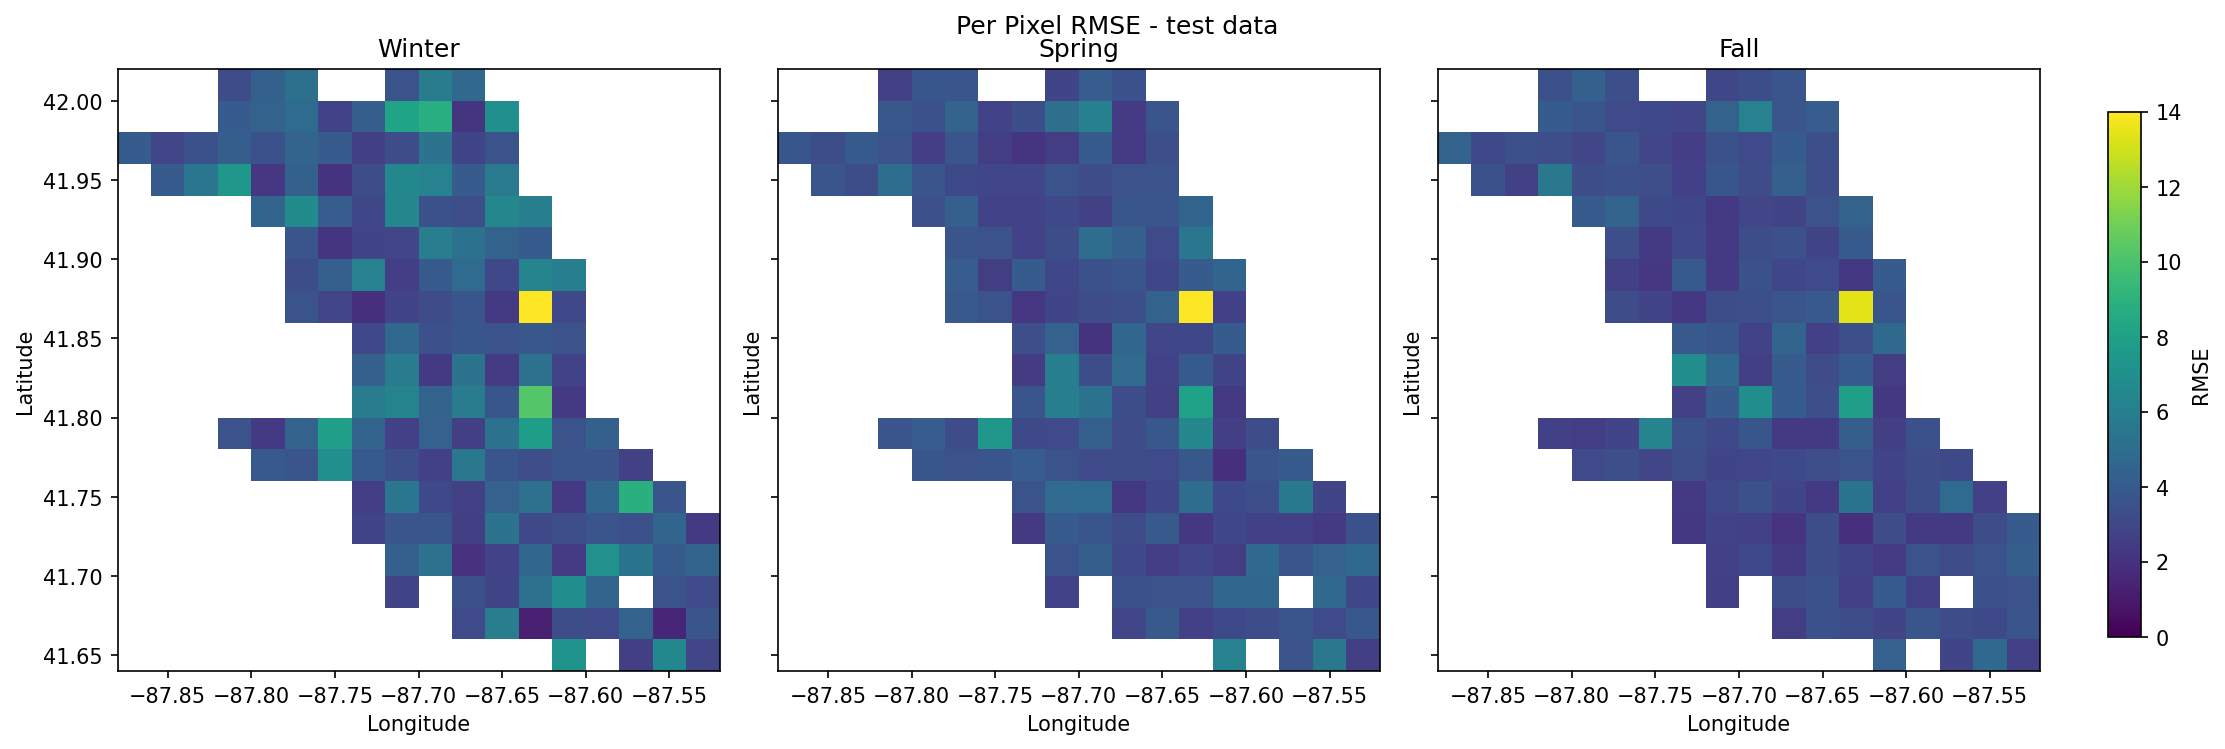

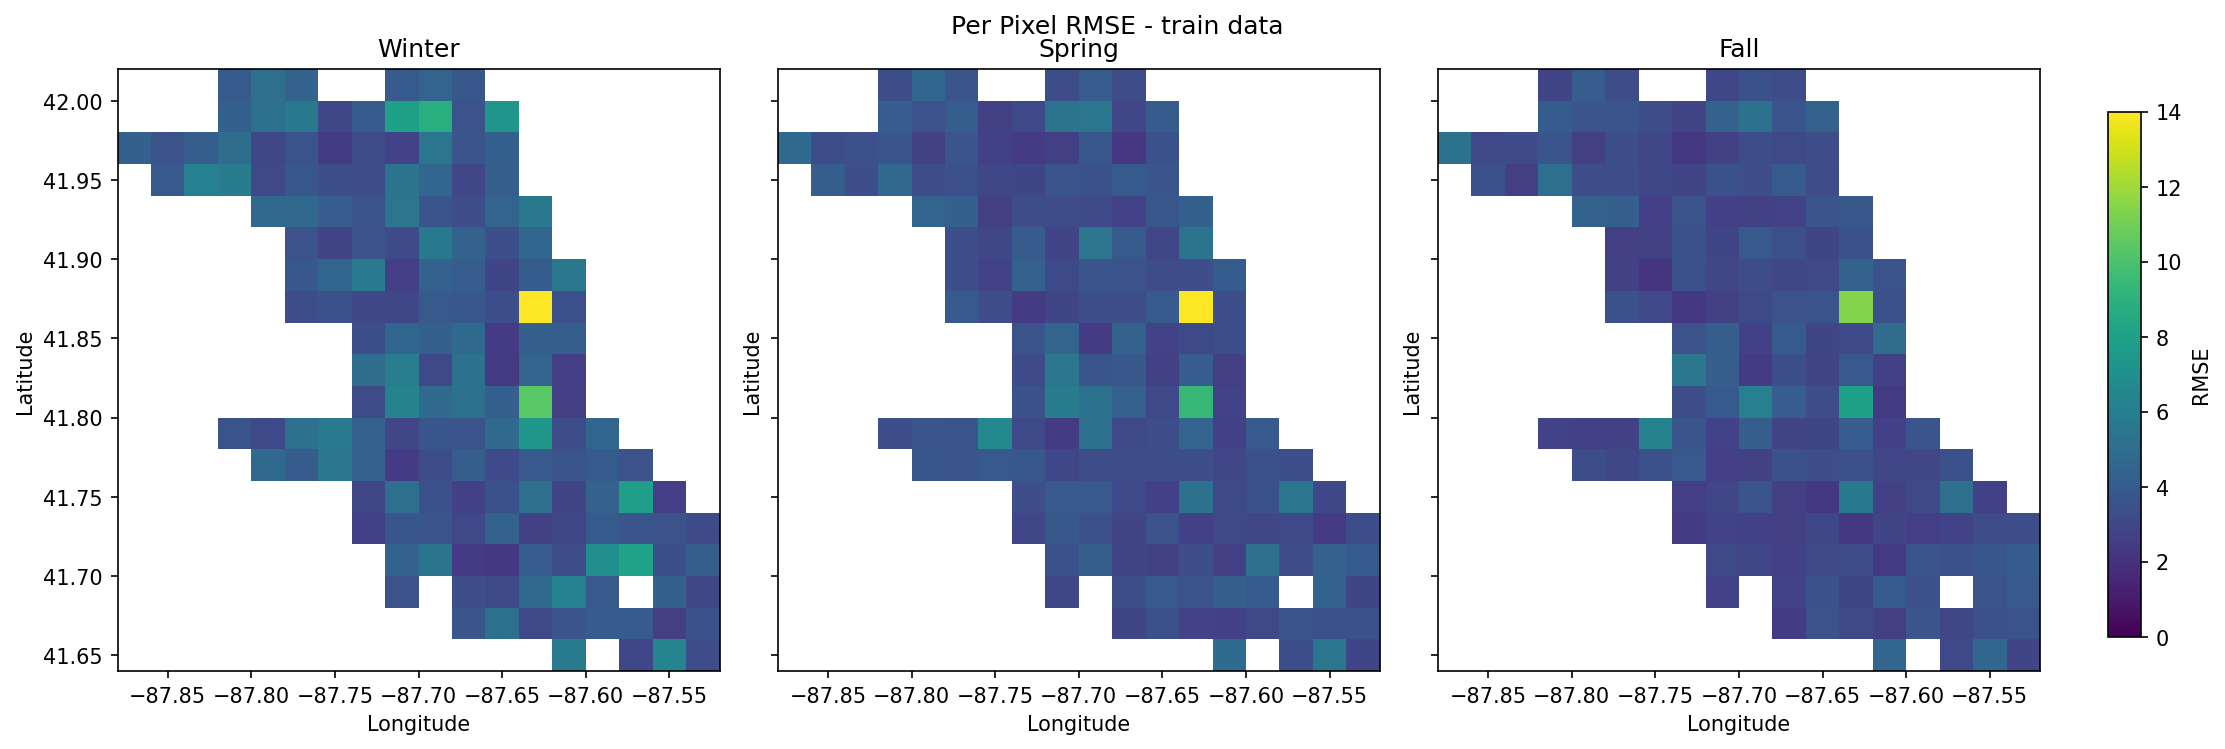

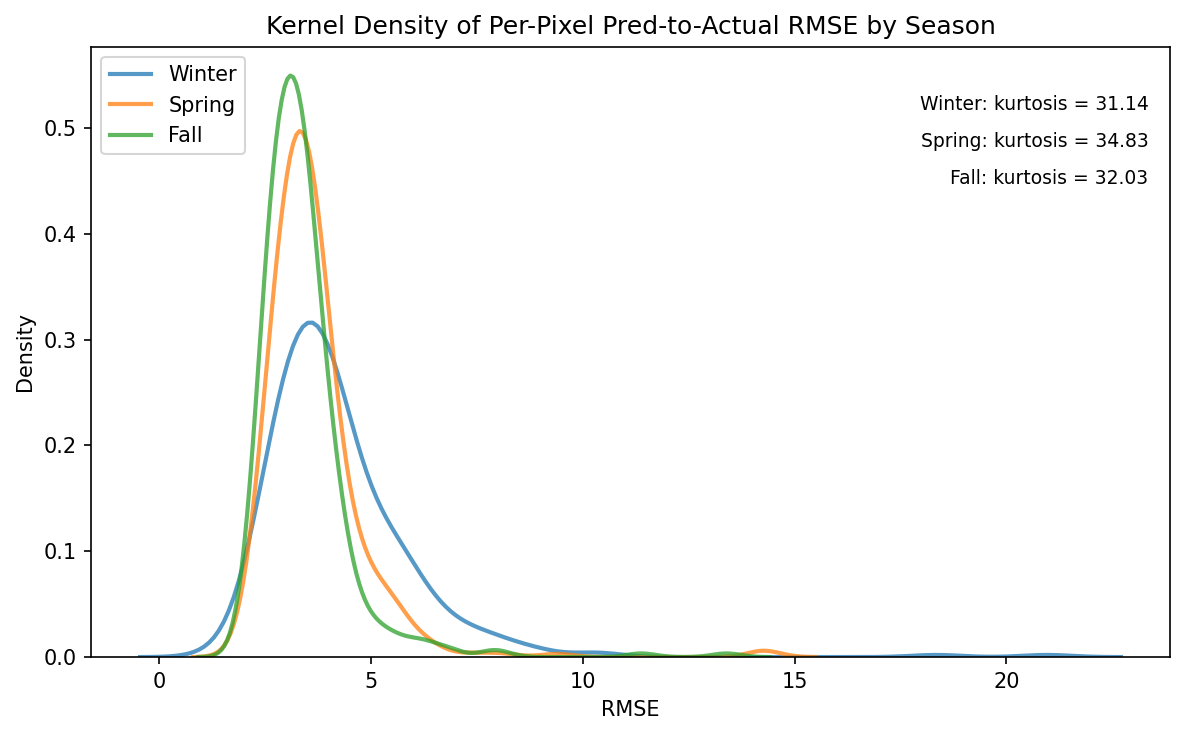

In [69]:
season_order = ['Winter', 'Spring', 'Summer', 'Fall']
splits = ['test','train']

for split in splits:
    seasonal_maps = []
    for season in season_order:
        season_subset = pixel_stats_long.loc[
            (pixel_stats_long['season'] == season) & (pixel_stats_long['variable'] == 'rmse') & (pixel_stats_long['split']==split),
            ['latitude', 'longitude', 'value']
        ]
        if season_subset.empty:
            continue

        season_rast = season_subset.set_index(['latitude', 'longitude']).to_xarray()
        seasonal_maps.append((season, season_rast['value']))

    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5), sharex=True, sharey=True)
    axes = axes.flatten()
    mappable = None

    for ax, (season, mean_map) in zip(axes, seasonal_maps):
        mappable = mean_map.plot(
            x='longitude',
            y='latitude',
            cmap='viridis',
            ax=ax,
            add_colorbar=False,
            vmin=0,
            vmax=14
        )
        ax.set_box_aspect(1)
        ax.set_title(season)
        ax.set_xlabel('Longitude')
        ax.set_ylabel('Latitude')

    for ax in axes[len(seasonal_maps):]:
        ax.set_visible(False)

    # Reserve space at right for a single shared colorbar
    plt.tight_layout(rect=[0, 0, 0.92, 0.97])

    if mappable is not None:
        cax = fig.add_axes([0.94, 0.15, 0.015, 0.7])
        fig.colorbar(mappable, cax=cax, label='RMSE')

    fig.suptitle('Per Pixel RMSE - '+split+' data')
    plt.savefig('seasonal-rmse-spatial-maps-'+split+'-data.png')
    plt.show()


seasonal_residuals = []

for season in season_order:
    if season not in pixel_stats_wide['season'].dropna().unique():
        continue

    season_values = pixel_stats_wide.loc[pixel_stats_wide['season'] == season, 'rmse'].dropna()
    if not season_values.empty:
        seasonal_residuals.append((season, season_values))

fig, ax = plt.subplots(figsize=(8, 5))

for i, (season, values) in enumerate(seasonal_residuals):
    sns.kdeplot(
        values,
        ax=ax,
        label=season,
        fill=False,
        alpha=0.75,
        linewidth=2
    )

    kurt = kurtosis(values, fisher=False, bias=False)
    ax.text(
        0.98,
        0.92 - 0.06 * i,
        f'{season}: kurtosis = {kurt:.2f}',
        transform=ax.transAxes,
        ha='right',
        va='top',
        fontsize=9,
    )

ax.set_title('Kernel Density of Per-Pixel Pred-to-Actual RMSE by Season')
ax.set_xlabel('RMSE')
ax.set_ylabel('Density')
ax.legend()
plt.tight_layout()
plt.savefig('kde-per-pixel-rmse-seasonal.png')
plt.show()


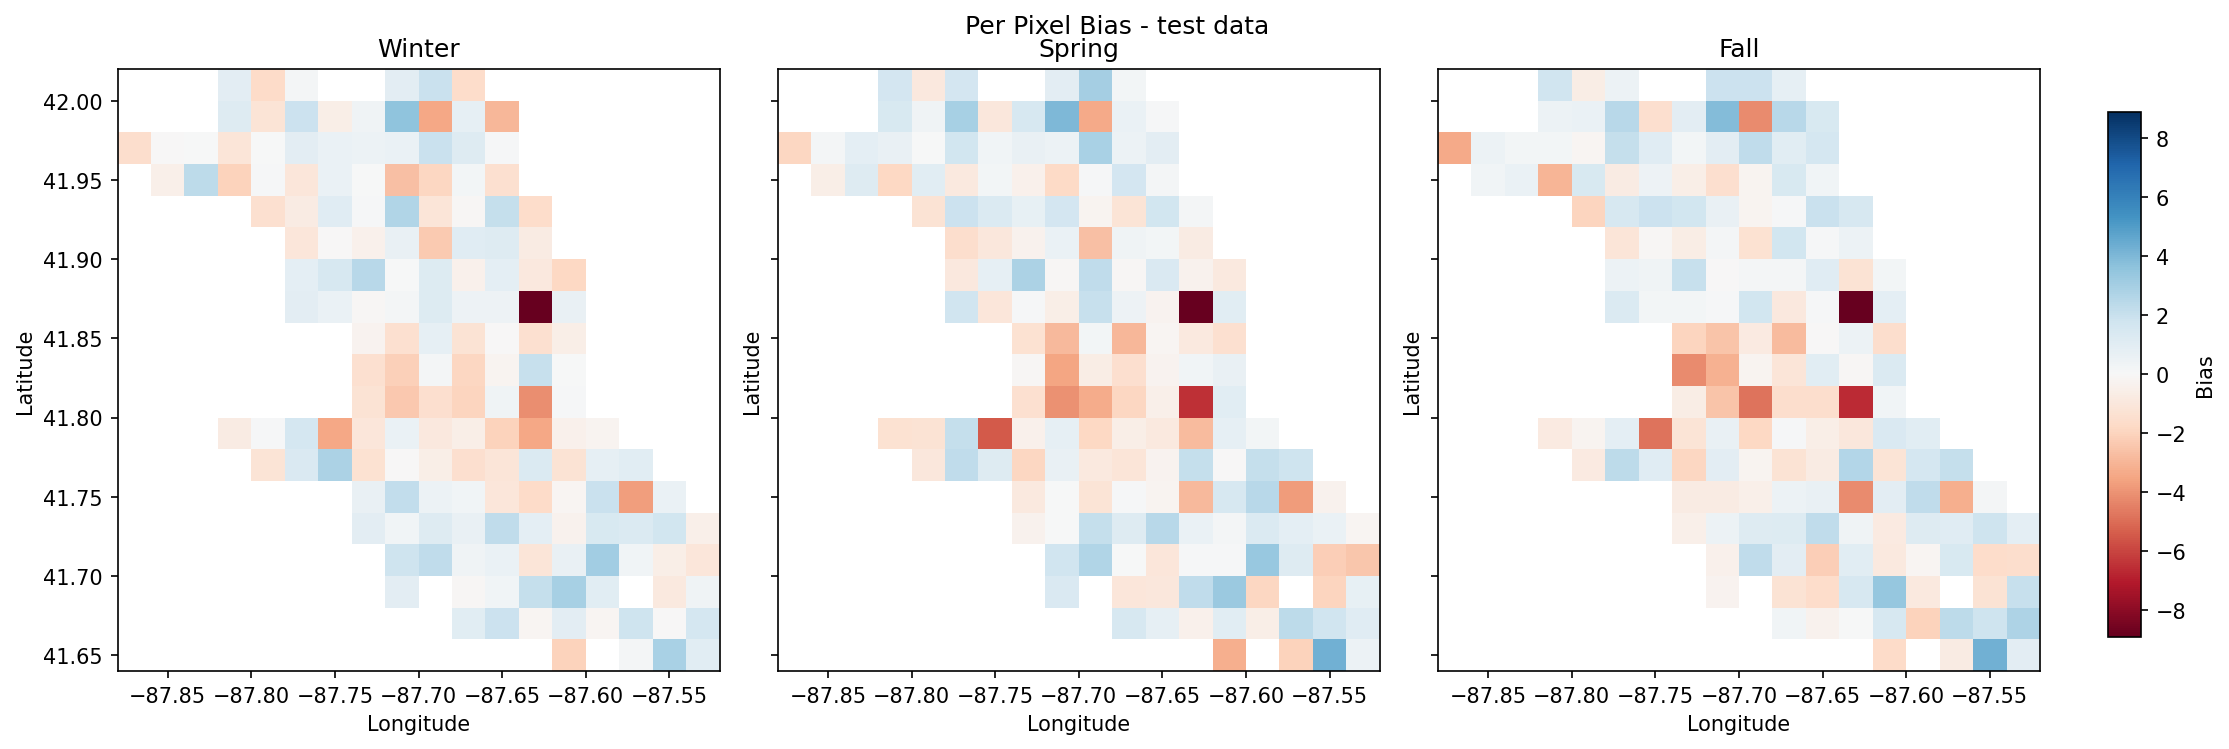

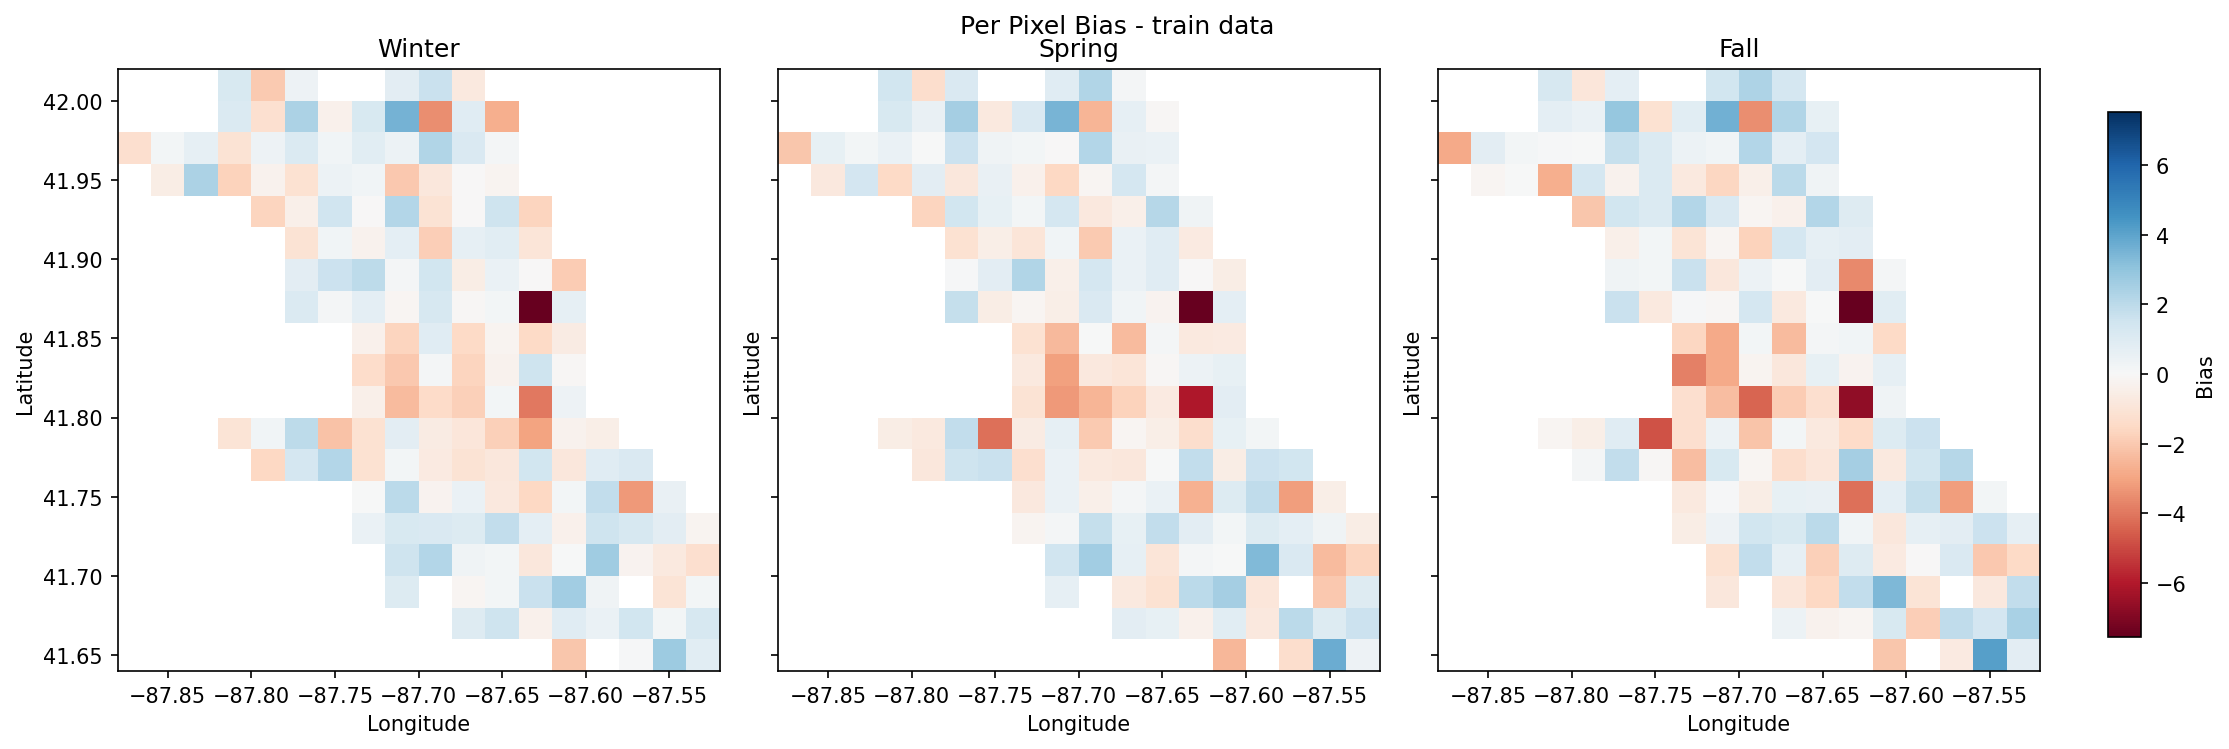

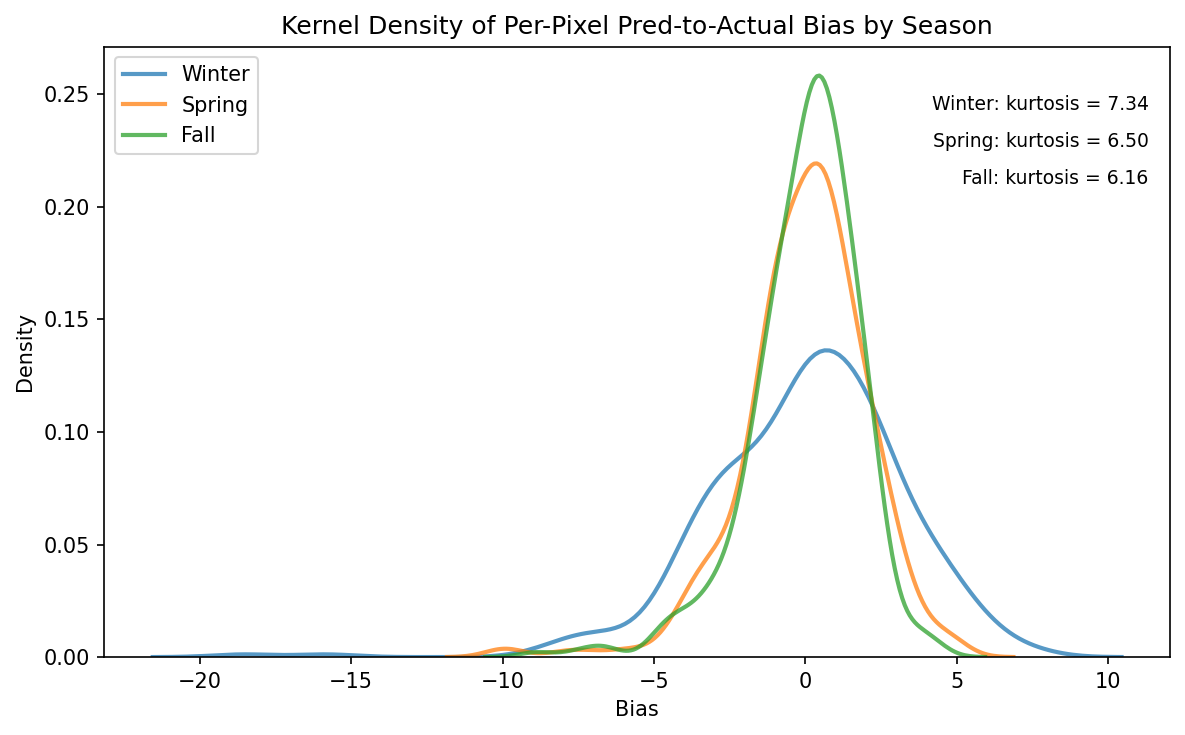

In [70]:

season_order = ['Winter', 'Spring', 'Summer', 'Fall']
splits = ['test','train']

for split in splits:
    seasonal_maps = []
    for season in season_order:
        season_subset = pixel_stats_long.loc[
            (pixel_stats_long['season'] == season) & (pixel_stats_long['variable'] == 'bias') & (pixel_stats_long['split']==split),
            ['latitude', 'longitude', 'value']
        ]
        if season_subset.empty:
            continue

        season_rast = season_subset.set_index(['latitude', 'longitude']).to_xarray()
        seasonal_maps.append((season, season_rast['value']))

    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5), sharex=True, sharey=True)
    axes = axes.flatten()
    mappable = None

    for ax, (season, mean_map) in zip(axes, seasonal_maps):
        mappable = mean_map.plot(
            x='longitude',
            y='latitude',
            cmap='RdBu',
            ax=ax,
            add_colorbar=False,
            # vmin=-20,
            # vmax=10
        )
        ax.set_box_aspect(1)
        ax.set_title(season)
        ax.set_xlabel('Longitude')
        ax.set_ylabel('Latitude')

    for ax in axes[len(seasonal_maps):]:
        ax.set_visible(False)

    # Reserve space at right for a single shared colorbar
    plt.tight_layout(rect=[0, 0, 0.92, 0.97])

    if mappable is not None:
        cax = fig.add_axes([0.94, 0.15, 0.015, 0.7])
        fig.colorbar(mappable, cax=cax, label='Bias')

    fig.suptitle('Per Pixel Bias - '+split+' data')
    plt.savefig('seasonal-bias-spatial-maps-'+split+'-data.png')
    plt.show()


seasonal_residuals = []

for season in season_order:
    if season not in pixel_stats_wide['season'].dropna().unique():
        continue

    season_values = pixel_stats_wide.loc[pixel_stats_wide['season'] == season, 'bias'].dropna()
    if not season_values.empty:
        seasonal_residuals.append((season, season_values))

fig, ax = plt.subplots(figsize=(8, 5))

for i, (season, values) in enumerate(seasonal_residuals):
    sns.kdeplot(
        values,
        ax=ax,
        label=season,
        fill=False,
        alpha=0.75,
        linewidth=2
    )

    kurt = kurtosis(values, fisher=False, bias=False)
    ax.text(
        0.98,
        0.92 - 0.06 * i,
        f'{season}: kurtosis = {kurt:.2f}',
        transform=ax.transAxes,
        ha='right',
        va='top',
        fontsize=9,
    )

ax.set_title('Kernel Density of Per-Pixel Pred-to-Actual Bias by Season')
ax.set_xlabel('Bias')
ax.set_ylabel('Density')
ax.legend()
plt.tight_layout()
plt.savefig('kde-per-pixel-bias-seasonal.png')
plt.show()

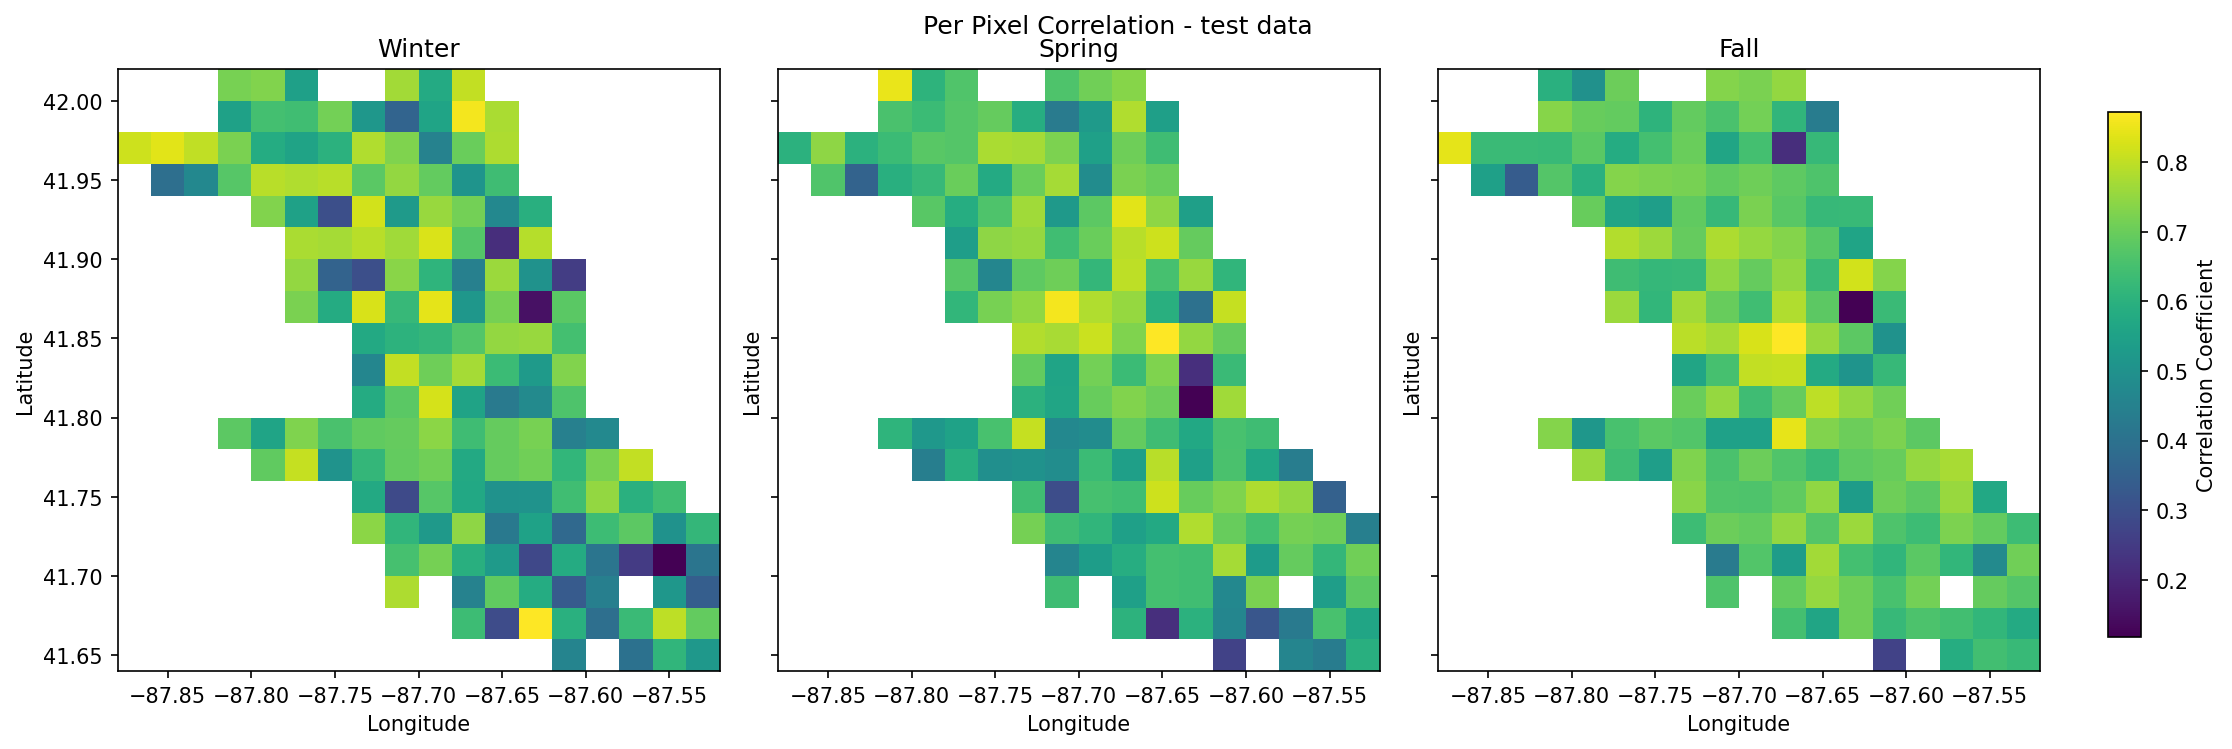

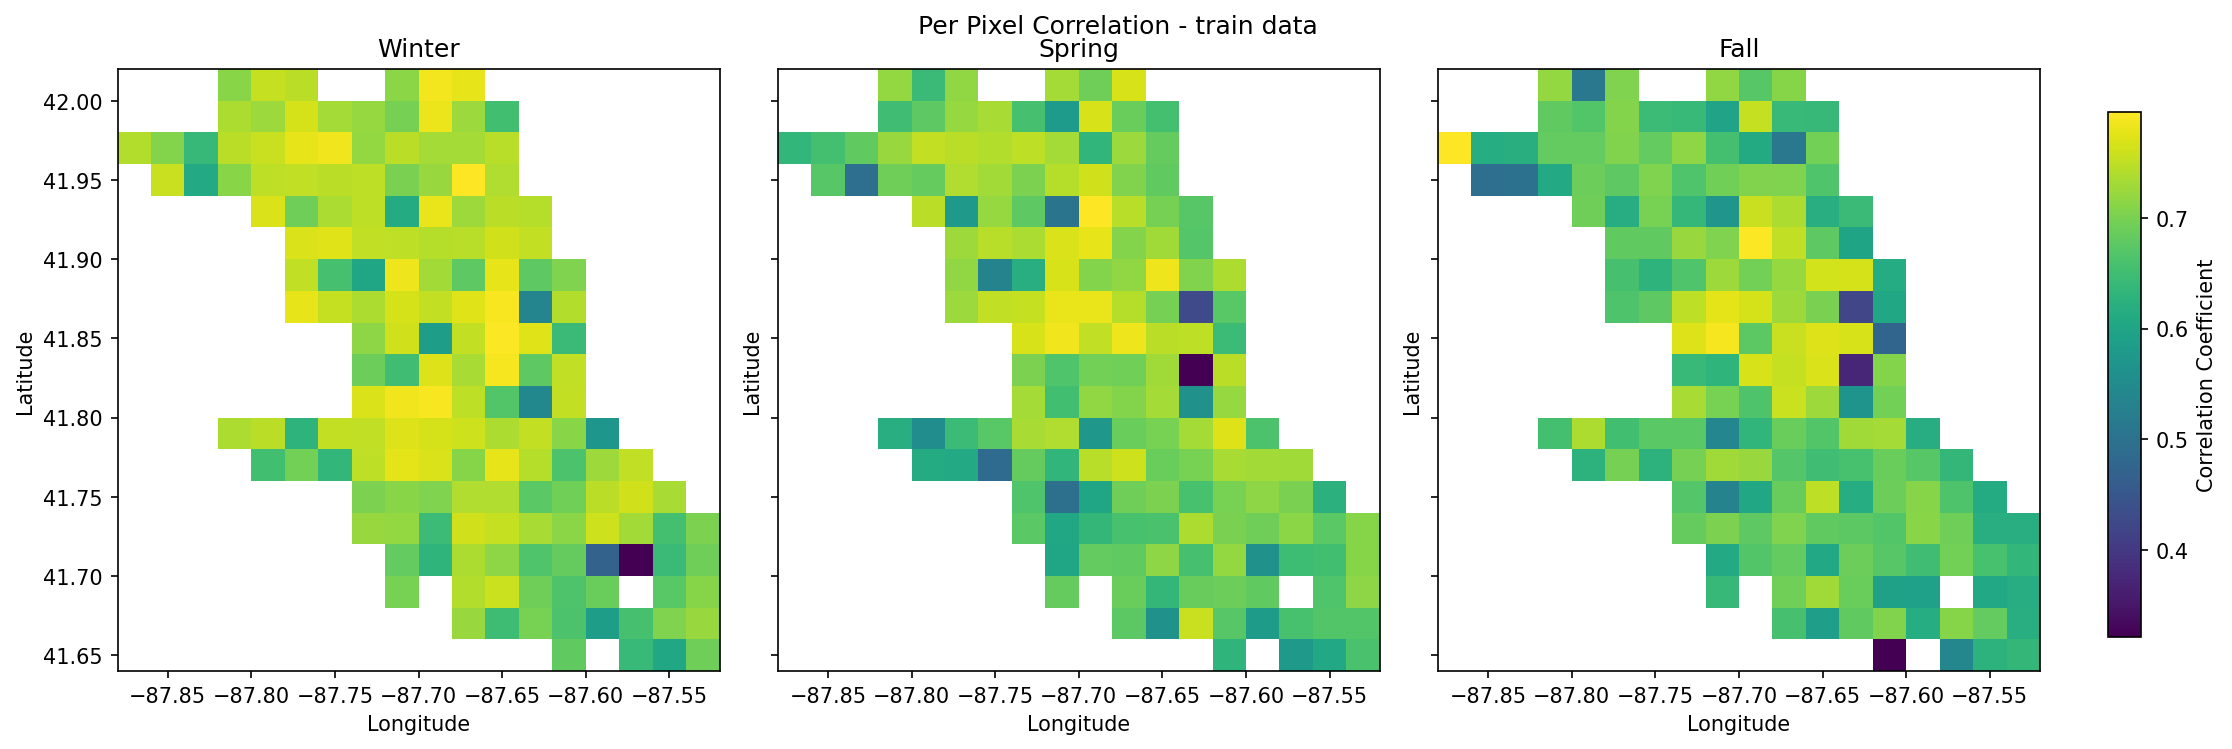

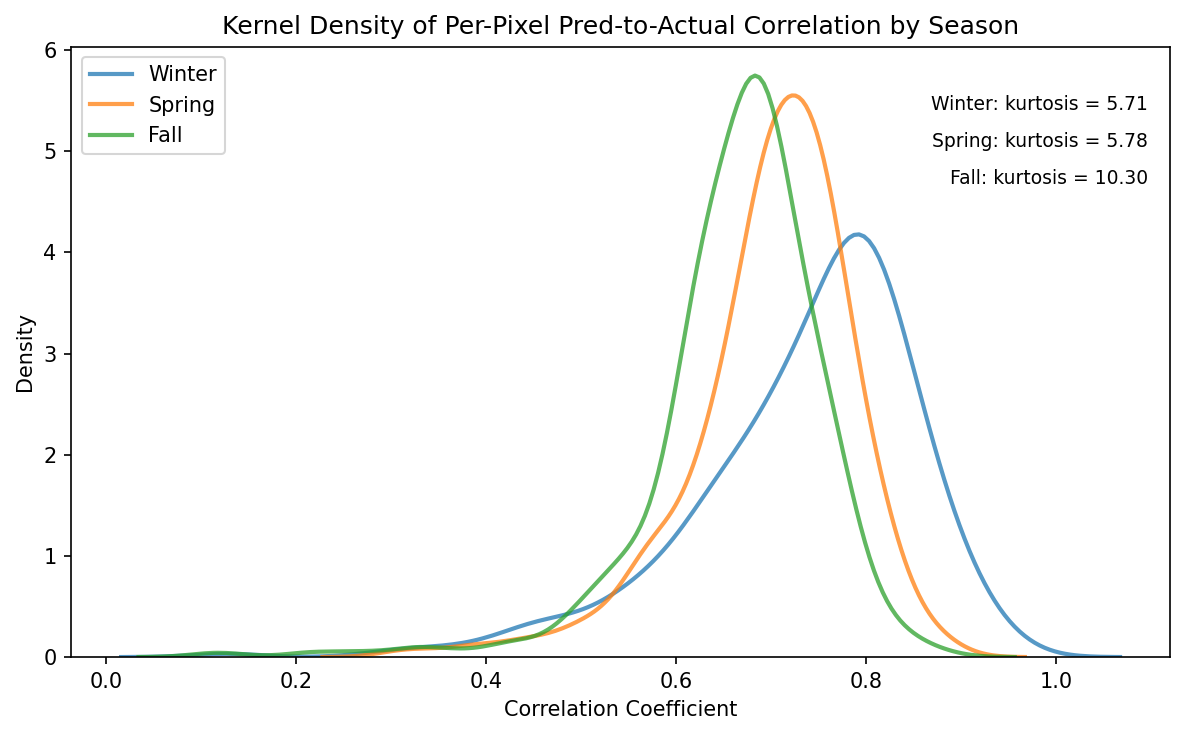

In [71]:

season_order = ['Winter', 'Spring', 'Summer', 'Fall']
splits = ['test','train']

for split in splits:
    seasonal_maps = []
    for season in season_order:
        season_subset = pixel_stats_long.loc[
            (pixel_stats_long['season'] == season) & (pixel_stats_long['variable'] == 'corr_coef') & (pixel_stats_long['split']==split),
            ['latitude', 'longitude', 'value']
        ]
        if season_subset.empty:
            continue

        season_rast = season_subset.set_index(['latitude', 'longitude']).to_xarray()
        seasonal_maps.append((season, season_rast['value']))

    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5), sharex=True, sharey=True)
    axes = axes.flatten()
    mappable = None

    for ax, (season, mean_map) in zip(axes, seasonal_maps):
        mappable = mean_map.plot(
            x='longitude',
            y='latitude',
            cmap='viridis',
            ax=ax,
            add_colorbar=False,
            # vmin=-20,
            # vmax=10
        )
        ax.set_box_aspect(1)
        ax.set_title(season)
        ax.set_xlabel('Longitude')
        ax.set_ylabel('Latitude')

    for ax in axes[len(seasonal_maps):]:
        ax.set_visible(False)

    # Reserve space at right for a single shared colorbar
    plt.tight_layout(rect=[0, 0, 0.92, 0.97])

    if mappable is not None:
        cax = fig.add_axes([0.94, 0.15, 0.015, 0.7])
        fig.colorbar(mappable, cax=cax, label='Correlation Coefficient')

    fig.suptitle('Per Pixel Correlation - '+split+' data')
    plt.savefig('seasonal-correlation-spatial-maps-'+split+'-data.png')
    plt.show()

seasonal_residuals = []

for season in season_order:
    if season not in pixel_stats_wide['season'].dropna().unique():
        continue

    season_values = pixel_stats_wide.loc[pixel_stats_wide['season'] == season, 'corr_coef'].dropna()
    if not season_values.empty:
        seasonal_residuals.append((season, season_values))

fig, ax = plt.subplots(figsize=(8, 5))

for i, (season, values) in enumerate(seasonal_residuals):
    sns.kdeplot(
        values,
        ax=ax,
        label=season,
        fill=False,
        alpha=0.75,
        linewidth=2
    )

    kurt = kurtosis(values, fisher=False, bias=False)
    ax.text(
        0.98,
        0.92 - 0.06 * i,
        f'{season}: kurtosis = {kurt:.2f}',
        transform=ax.transAxes,
        ha='right',
        va='top',
        fontsize=9,
    )

ax.set_title('Kernel Density of Per-Pixel Pred-to-Actual Correlation by Season')
ax.set_xlabel('Correlation Coefficient')
ax.set_ylabel('Density')
ax.legend()
plt.tight_layout()
plt.savefig('kde-per-pixel-correlations-seasonal.png')
plt.show()